In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una obra de reforma de una nave industrial comprende las actividades del cuadro adjunto (duraciones en semanas). La actividad **D** es la demolición de la cubierta y de la estructura ligera; la cubierta son **1900 m² de placas de fibrocemento con amianto**, que el plan trata como parte de la demolición. La obra empieza en la semana 1, al firmar el contrato; el jefe de obra prevé elegir entonces a los subcontratistas, aunque la adjudicación se conoce varias semanas antes.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 1       ),
    ('B'     , '---'      , 6       ),
    ('C'     , '---'      , 2       ),
    ('D'     , 'A,B,C'    , 6       ),
    ('E'     , 'A'        , 2       ),
    ('F'     , 'D'        , 5       ),
    ('G'     , 'E,F'      , 4       ),
    ('H'     , 'F'        , 5       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,1
B,---,6
C,---,2
D,"A,B,C",6
E,A,2
F,D,5
G,"E,F",4
H,F,5


La retirada de la cubierta por una empresa inscrita en el RERA (plan de trabajo, equipos de protección, embalaje y gestor de residuos peligrosos) cuesta 30 k€ y dura 1 semana(s); el plan de trabajo se presenta a la autoridad laboral cuando se contrata a la empresa y tarda **7 semanas** en quedar aprobado (45 días). Quitar las placas con la cuadrilla de peones un sábado y llevarlas en el contenedor de escombros costaría 4 k€. La penalidad por retraso de la entrega es de 6 k€ por semana. Por la experiencia de la empresa, una retirada sin plan ni empresa inscrita acaba en visita de la Inspección de Trabajo con probabilidad 70%: paralización de la obra 4 semanas y sanción de 80 k€, además del riesgo para los operarios.

> **De: Jefe de obra**
> La uralita la quitan los peones el sábado, con mascarilla y mojándola, y al contenedor; en D ya está contada la demolición. Lo de la empresa de amianto son 30 k€ y 7 semanas de papeleo que no tenemos: el plan ya va justo.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S17 — Actividades exigidas por una norma: tienen duración y van en el cronograma.** Un trámite o trabajo que la norma exige antes de otro (un plan de trabajo aprobado por la autoridad laboral, la retirada de un material peligroso por una empresa inscrita, la evaluación de una modificación del proyecto) es una actividad del cronograma con su duración legal y su prelación. Omitirla no acorta el proyecto: lo deja sin autorización. Cuántas semanas de retraso causa y con cuánta antelación habría que lanzarla lo dice el calendario (lección 05), y es una cuenta, no una opinión (cf. C7 de la lección 19). *(cf. RD 396/2006, arts. 11, 12.2 y 17.1; Ley 21/2013, art. 7.2.c); PMBOK 8 §3.7.3 (dominio del cronograma).)*
- **S10 — Condiciones de trabajo en la cadena de ejecución.** El plan no puede apoyarse en condiciones de trabajo que la norma prohíbe: ni en una cadena de subcontratación más larga que la permitida, ni en jornadas al aire libre que ignoren los avisos por calor extremo. Una ventaja de coste o plazo obtenida así no es una opción de la tabla (cf. C7 y C5 de la lección 19). *(cf. Ley 32/2006 de subcontratación en la construcción, arts. 4 y 5; RD 486/1997, disposición adicional única (RDL 4/2023); ICB4, Perspectiva 3 «salud, seguridad y medio ambiente».)*
- **S8 — Jerarquía de residuos y separación en origen.** El orden es prevención, preparación para la reutilización, reciclado, otra valorización y, en último lugar, eliminación. Los residuos de construcción y demolición no peligrosos se clasifican, preferentemente en la obra, en al menos seis fracciones (madera, minerales, metales, vidrio, plástico y yeso) y la demolición es selectiva, previo estudio de las cantidades de cada fracción. Mezclarlo todo en un contenedor que va a vertedero es elegir el último escalón e incumplir la obligación de clasificar. *(cf. Ley 7/2022 de residuos y suelos contaminados, arts. 8 y 30; RD 105/2008 (estudio y plan de gestión de RCD).)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — antes de empezar cualquier trabajo con riesgo de exposición al amianto (la retirada de cubiertas de fibrocemento incluida) el empresario elabora un plan de trabajo y lo presenta a la autoridad laboral, que resuelve en 45 días desde la entrada en su registro (transcurridos sin resolución expresa, el plan se entiende aprobado); sólo pueden hacerlo empresas inscritas en el Registro de Empresas con Riesgo por Amianto (RERA); los residuos con amianto son peligrosos (LER 17 06 05*) y se embalan, etiquetan y entregan a gestor autorizado sin mezclarlos con otros residuos** *(RD 396/2006, arts. 11, 12.2 y 17.1; Ley 7/2022, arts. 20 y 21; Decisión 2014/955/UE (lista europea de residuos).)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Añada al cuadro las actividades que la norma exige: P, plan de trabajo aprobado (7 semanas desde el inicio, sin predecesoras) y R, retirada de la cubierta por la empresa inscrita (1 semana(s), después de P y de las predecesoras de D), de modo que D empiece tras R. Calcule la nueva duración, la ruta crítica y el retraso respecto al plan.  "
pregunta_2 = "2. (A) ¿Cuántas semanas antes del inicio habría que presentar el plan de trabajo para que el retraso fuera sólo el de la retirada (1 semana(s))? Calcule el coste de las opciones: retirada legal con el retraso, retirada legal con el plan presentado con antelación, y la propuesta de los peones con su coste esperado.  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿pueden los peones retirar la cubierta? ¿Es la aprobación del plan de trabajo una actividad del cronograma o «papeleo»? ¿Dónde va el residuo? ¿En qué escalón de la pirámide queda la propuesta?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y a la dirección facultativa? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Añada al cuadro las actividades que la norma exige: P, plan de trabajo aprobado (7 semanas desde el inicio, sin predecesoras) y R, retirada de la cubierta por la empresa inscrita (1 semana(s), después de P y de las predecesoras de D), de modo que D empiece tras R. Calcule la nueva duración, la ruta crítica y el retraso respecto al plan.  

2. (A) ¿Cuántas semanas antes del inicio habría que presentar el plan de trabajo para que el retraso fuera sólo el de la retirada (1 semana(s))? Calcule el coste de las opciones: retirada legal con el retraso, retirada legal con el plan presentado con antelación, y la propuesta de los peones con su coste esperado.  

3. (B) Según el criterio y la norma de referencia, ¿pueden los peones retirar la cubierta? ¿Es la aprobación del plan de trabajo una actividad del cronograma o «papeleo»? ¿Dónde va el residuo? ¿En qué escalón de la pirámide queda la propuesta?  

4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y a la dirección facultativa? Aplique la rúbrica.  

# Resolución

In [6]:
demolicion, semanas_plan, semanas_retirada, coste_rera, coste_peones, penalidad, p_inspeccion, multa, paralizacion = 'D', 7, 1, 30, 4, 6, 0.7, 80, 4
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

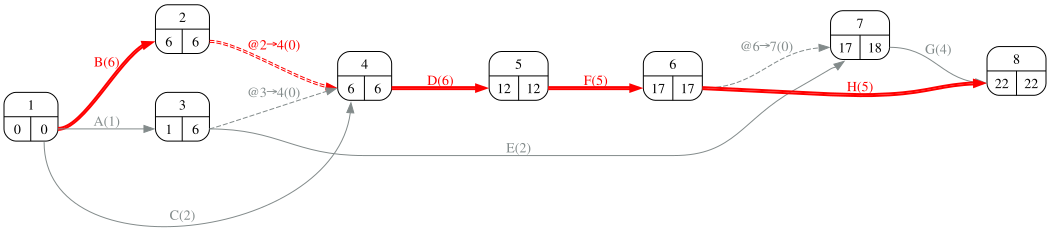

In [8]:
#| fig-cap: "Grafo PERT del plan presentado"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Añada al cuadro las actividades que la norma exige: P, plan de trabajo aprobado (7 semanas desde el inicio, sin predecesoras) y R, retirada de la cubierta por la empresa inscrita (1 semana(s), después de P y de las predecesoras de D), de modo que D empiece tras R. Calcule la nueva duración, la ruta crítica y el retraso respecto al plan.  

In [10]:
#| tbl-cap: "Cuadro con el plan de trabajo (P) y la retirada (R) delante de la demolición"
#| label: tbl-datosLegal
datos_legal = datos_proyecto.copy()
pred_y = datos_legal.loc[demolicion, 'predecessor']
datos_legal.loc['P'] = ['---', semanas_plan]
datos_legal.loc['R'] = ['P' if pred_y == '---' else pred_y + ',P', semanas_retirada]
datos_legal.loc[demolicion, 'predecessor'] = 'R'
datos_legal['duration'] = datos_legal['duration'].astype(int)
display(datos_legal)
prelaciones_legal = PredecessorTable.from_dataframe_of_strings(datos_legal, activity='activity', predecessor='predecessor')
proyecto_legal = prelaciones_legal.create_project()
calendario_legal = proyecto_legal.calendar(datos_legal['duration'])
duracion_legal = int(proyecto_legal.duration(datos_legal['duration']))
retraso = duracion_legal - duracion

,predecessor,duration
activity,,
A,---,1
B,---,6
C,---,2
D,R,6
E,A,2
F,D,5
G,"E,F",4
H,F,5
P,---,7


Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

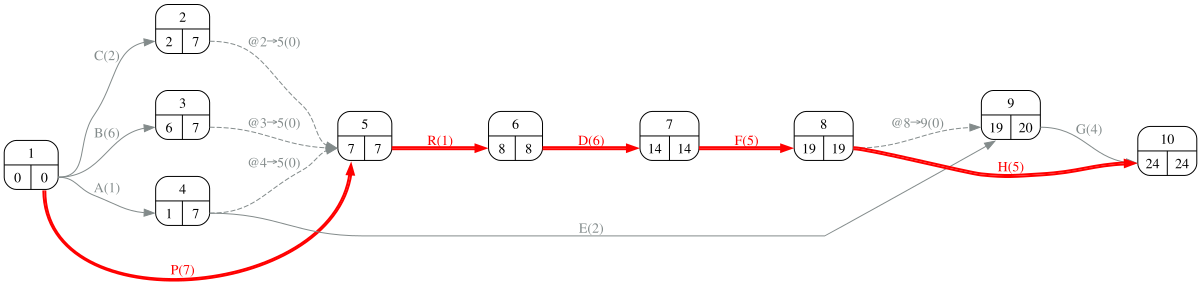

In [11]:
#| fig-cap: "Grafo PERT con el plan de trabajo y la retirada"
#| label: fig-pertLegal
proyecto_legal.display_pert_pasos(datos_legal['duration'])

In [12]:
#| tbl-cap: "Calendario con las actividades exigidas por la norma"
#| label: tbl-calendarioLegal
display(calendario_legal)
camino = ' / '.join('–'.join(r) for r in proyecto_legal.critical_path(datos_legal['duration']).values())
Markdown(f'''El proyecto pasa de {duracion} a **{duracion_legal}** semanas (ruta crítica {camino}): **{retraso}** semana(s) de retraso, {retraso * penalidad} k€ de penalidad. El plan de trabajo (P) entra en la ruta crítica: {demolicion} no puede empezar hasta la semana {int(calendario_legal.loc[demolicion, 'inicio_mas_temprano'])} en vez de la {int(calendario.loc[demolicion, 'inicio_mas_temprano'])}.''')

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,6,1,7,0,0,6,1
B,0,1,6,7,0,0,1,6
C,0,5,2,7,0,0,5,2
D,8,8,14,14,0,0,0,6
E,1,18,3,20,16,10,17,2
F,14,14,19,19,0,0,0,5
G,19,20,23,24,1,0,1,4
H,19,19,24,24,0,0,0,5
P,0,0,7,7,0,0,0,7


El proyecto pasa de 22 a **24** semanas (ruta crítica D–F–H–P–R): **2** semana(s) de retraso, 12 k€ de penalidad. El plan de trabajo (P) entra en la ruta crítica: D no puede empezar hasta la semana 8 en vez de la 6.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) ¿Cuántas semanas antes del inicio habría que presentar el plan de trabajo para que el retraso fuera sólo el de la retirada (1 semana(s))? Calcule el coste de las opciones: retirada legal con el retraso, retirada legal con el plan presentado con antelación, y la propuesta de los peones con su coste esperado.  

In [14]:
es_y = int(calendario.loc[demolicion, 'inicio_mas_temprano'])
adelanto = max(0, semanas_plan - es_y)
opciones = pd.Series({'retirada legal, plan presentado al empezar': coste_rera + retraso * penalidad,
                      f'retirada legal, plan presentado {adelanto} semana(s) antes': coste_rera + semanas_retirada * penalidad,
                      'peones el sábado (propuesta): coste esperado': coste_peones + p_inspeccion * (multa + paralizacion * penalidad)})
display(opciones.round(1).to_frame('coste (k€)'))
Markdown(f'''{demolicion} empezaría en la semana {es_y}: presentando el plan **{adelanto} semana(s) antes del inicio** (en cuanto se adjudique, con la empresa inscrita ya elegida) el retraso se reduce a la semana de la retirada, {semanas_retirada * penalidad} k€. La propuesta de los peones cuesta {opciones.iloc[2]:.1f} k€ esperados''' + (', más que la vía legal con antelación: mal negocio además de infracción.' if opciones.iloc[2] > opciones.iloc[1] else ', menos que la vía legal: la respuesta B no depende de esta cuenta.'))

,coste (k€)
"retirada legal, plan presentado al empezar",42.0
"retirada legal, plan presentado 1 semana(s) antes",36.0
peones el sábado (propuesta): coste esperado,76.8


D empezaría en la semana 6: presentando el plan **1 semana(s) antes del inicio** (en cuanto se adjudique, con la empresa inscrita ya elegida) el retraso se reduce a la semana de la retirada, 6 k€. La propuesta de los peones cuesta 76.8 k€ esperados, más que la vía legal con antelación: mal negocio además de infracción.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿pueden los peones retirar la cubierta? ¿Es la aprobación del plan de trabajo una actividad del cronograma o «papeleo»? ¿Dónde va el residuo? ¿En qué escalón de la pirámide queda la propuesta?  

**Norma y S17.** Los trabajos con riesgo de exposición al amianto sólo pueden hacerlos empresas inscritas en el RERA (RD 396/2006, art. 17.1) con un plan de trabajo aprobado por la autoridad laboral antes de empezar (arts. 11 y 12): los peones **no pueden** retirar la cubierta, con mascarilla o sin ella. El plan de trabajo no es papeleo: es una actividad con duración legal (45 días, art. 12.2, con silencio positivo) y prelación (antes de la retirada, que es antes de D), y su efecto en el plazo es una cuenta: 2 semana(s) si se presenta al empezar, 1 si se presenta 1 semana(s) antes. Que «en D ya está contada la demolición» es la trampa: contaba una demolición que la ley no permite hacer así. **S8.** El residuo con amianto es **peligroso** (LER 17 06 05*): embalado y etiquetado, a gestor autorizado, sin mezclar con otros residuos (Ley 7/2022, arts. 20 y 21); «al contenedor de escombros» contamina el contenedor entero y es infracción. **S10.** El plan no puede apoyarse en exponer a la cuadrilla a un cancerígeno para ahorrar 26 k€: no es una opción de la tabla. **S1.** La propuesta traslada el impacto a los operarios (y, con el contenedor, al gestor y al vertedero): ni siquiera compensa. La vía legal con el plan presentado a tiempo **minimiza** el efecto en el plazo; **evitar** sería haber tenido en el cronograma P y R desde el principio.

In [16]:
preguntas_test = [
    ('La retirada de una cubierta de fibrocemento con amianto puede hacerla…', ['sólo una empresa inscrita en el RERA, con un plan de trabajo aprobado por la autoridad laboral antes de empezar', 'cualquier cuadrilla con mascarilla, mojando las placas', 'el contratista principal si la obra es pequeña', 'cualquier empresa si lo autoriza la dirección facultativa'],
     'RD 396/2006, arts. 11, 12 y 17.'),
    ('La autoridad laboral resuelve sobre el plan de trabajo con amianto…', ['en 45 días desde la entrada en su registro; sin resolución expresa, se entiende aprobado', 'en 10 días', 'no hace falta resolución: basta presentarlo', 'en el plazo que fije el contratista'],
     'Art. 12.2 del RD 396/2006: para el cronograma son unas 7 semanas desde la presentación.'),
    ('Si un trámite obligatorio de duración d debe terminar antes de una actividad crítica que empieza en la semana ES, el proyecto se retrasa…', ['máx(0, d − ES) semanas (más la duración de lo que el trámite habilita), salvo que el trámite se lance con antelación', 'd semanas siempre', 'nada, porque los trámites van en paralelo', 'ES semanas'],
     'S17 y lección 05: el calendario dice cuánto y con qué antelación.'),
    ('Los residuos con amianto de una obra son…', ['residuos peligrosos: embalados, etiquetados y entregados a gestor autorizado sin mezclar', 'residuos inertes', 'residuos de construcción ordinarios si están mojados', 'residuos municipales'],
     'LER 17 06 05*; Ley 7/2022, arts. 20 y 21.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — amianto')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Sostenibilidad 20 — amianto

::Sostenibilidad 20 — amianto P1::La retirada de una cubierta de fibrocemento con amianto puede hacerla… {=sólo una empresa inscrita en el RERA, con un plan de trabajo aprobado por la autoridad laboral antes de empezar ~cualquier cuadrilla con mascarilla, mojando las placas ~el contratista principal si la obra es pequeña ~cualquier empresa si lo autoriza la dirección facultativa ####RD 396/2006, arts. 11, 12 y 17.}

::Sostenibilidad 20 — amianto P2::La autoridad laboral resuelve sobre el plan de trabajo con amianto… {~en el plazo que fije el contratista =en 45 días desde la entrada en su registro; sin resolución expresa, se entiende aprobado ~no hace falta resolución: basta presentarlo ~en 10 días ####Art. 12.2 del RD 396/2006: para el cronograma son unas 7 semanas desde la presentación.}

::Sostenibilidad 20 — amianto P3::Si un trámite obligatorio de duración d debe terminar antes de una actividad crítica que empieza en la semana ES, el proyecto

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de obra y qué comunica al cliente y a la dirección facultativa? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de obra: el cuadro del apartado 1 con P y R, la empresa inscrita elegida hoy y el plan de trabajo presentado hoy (cada semana que se tarde es una semana de retraso), y la lista de lo que sí se puede adelantar mientras se tramita (todo lo que no depende de D). Al cliente: la cubierta de amianto que el proyecto no había contado como tal, el plazo legal y el efecto en la entrega (2 semanas, o 1 si se tramita con antelación), con la petición de revisar la penalidad por una obligación que estaba en la nave antes de firmar. A la dirección facultativa: el plan de trabajo y el estudio de gestión de residuos con el residuo peligroso. Prueba de publicidad: ¿explicaría a la Inspección de Trabajo, con un parte de exposición de la cuadrilla encima de la mesa, que la uralita «se quitó mojada»?